# 02: Separating Driver from Car

The first notebook established *what* to measure: each driver's best Q1 lap, expressed as a
percentage gap to the fastest lap of that session. This one estimates how much of that gap comes
from the driver and how much from the car.

### The identification problem

A driver's lap time reflects their skill *and* their machinery, and you never see the two apart. If
Verstappen is quick in a Red Bull, is that Verstappen or the Red Bull?

The answer comes from **drivers changing teams**. When a driver moves from one constructor to
another, their pace relative to the field shifts, and how much it shifts tells you how much of
their performance travelled with them (skill) versus stayed behind (car). Chain enough of those
moves together and every driver and constructor becomes connected in one network.

This is what a **hierarchical model** does naturally: it estimates a per-driver effect and a
per-constructor effect simultaneously, letting the team-switchers carry the information that pulls
them apart.

### Why Bayesian

Two reasons, both practical rather than ideological:

1. **Uncertainty is the point.** A driver with 8 sessions and a driver with 150 shouldn't be ranked
   as though we know both equally well. A Bayesian model reports a full distribution per driver, so
   "we don't really know" is a statable answer rather than a hidden caveat.
2. **Partial pooling handles thin data.** Rather than trusting a rookie's handful of races at face
   value, the model pulls sparse estimates toward the overall average and only lets well-observed
   drivers move far from it.

**Contents:**
1. Setup and data.
2. What the model has to work with.
3. Prior predictive check.
4. Fitting the first model.
5. Convergence diagnostics.
6. Posterior predictive check.
7. Comparing candidate likelihoods.
8. Modelling on the square-root scale.
9. Quantified takeaways.

## Setup and data

`q1_pace.csv` is the output of notebook 01, uploaded here as a Kaggle dataset. Bambi provides a
formula interface (like R's lme4) on top of PyMC, which keeps the model specification readable.

In [19]:
!pip install -q bambi arviz

import pandas as pd
import numpy as np
import bambi as bmb
import arviz as az
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
print('bambi', bmb.__version__, '| arviz', az.__version__)

bambi 0.20.0 | arviz 1.3.0


In [20]:
import glob

csv_path = glob.glob('/kaggle/input/**/*.csv', recursive=True)[0]
print('loading:', csv_path)

pace = pd.read_csv(csv_path)
print(pace.shape)
pace.head()

loading: /kaggle/input/datasets/mikandr/q1-pace/q1_pace.csv
(3029, 9)


,season,gp,team,drv,best_lap,n_valid_laps,gap_to_fastest,rain_fraction,within_107
0,2018,Abu Dhabi Grand Prix,Ferrari,RAI,97.010,3,0.242831,0.0,True
1,2018,Abu Dhabi Grand Prix,Ferrari,VET,96.775,3,0.000000,0.0,True
2,2018,Abu Dhabi Grand Prix,Haas F1 Team,GRO,97.575,1,0.826660,0.0,True
3,2018,Abu Dhabi Grand Prix,Haas F1 Team,MAG,97.934,2,1.197623,0.0,True
4,2018,Abu Dhabi Grand Prix,McLaren,ALO,97.890,3,1.152157,0.0,True


## What the model has to work with

Before fitting anything, I check the structure that makes driver-versus-car separation possible at
all, how many sessions each driver has, and how many drivers each constructor has fielded.

In [21]:
model_data = pace[pace['within_107']].copy()
print('rows:', len(model_data), 'of', len(pace), '(107% rule applied)')
print('drivers:', model_data['drv'].nunique(),
      '| constructors:', model_data['team'].nunique(),
      '| seasons:', model_data['season'].nunique())
print()
print('sessions per driver:')
print(model_data['drv'].value_counts().describe().round(1))

rows: 3008 of 3029 (107% rule applied)
drivers: 43 | constructors: 19 | seasons: 8

sessions per driver:
count     43.0
mean      70.0
std       53.7
min        1.0
25%       22.0
50%       59.0
75%      122.5
max      154.0
Name: count, dtype: float64


In [22]:
teams_per_driver = model_data.groupby('drv')['team'].nunique()
print('constructors driven for, per driver:')
print(teams_per_driver.value_counts().sort_index().rename('n_drivers'))
print()
print(f'drivers who switched constructor: {(teams_per_driver > 1).sum()} of {len(teams_per_driver)}')

constructors driven for, per driver:
team
1    20
2    11
3     6
4     3
5     3
Name: n_drivers, dtype: int64

drivers who switched constructor: 23 of 43


### What this tells me

Sessions per driver run from **1 to 154** (median 59). One driver appears exactly once. A plain
per-driver average would treat that single session as though it were as informative as another
driver's 154, which is the specific failure partial pooling prevents.

And **23 of 43 drivers switched constructor**, which is the entire basis for separating skill from
car. The other 20 are locked to one team, so nothing in their record distinguishes "good driver"
from "good car". The model can still estimate them, but with wide intervals, and that limitation
belongs in any ranking I report.

## Prior predictive check

### Reading the model formula

The model is written as:

```
gap_to_fastest ~ 1 + (1|drv) + (1|team) + (1|season)
```

Read left to right: predict a driver's percentage gap from an overall average (`1`), plus an offset
for *who* is driving, plus an offset for *which team*, plus an offset for *which season*.

The `(1|x)` notation means those offsets aren't estimated independently. Each set is drawn from a
shared distribution whose spread the model also estimates, so instead of 43 unrelated driver
numbers, there's one "how much do drivers differ?" parameter governing all of them. That shared
spread is what does the pooling, and its size is the answer to the driver-versus-car question.

### Checking the priors first

Before fitting, it's worth asking what the model believes *before seeing any data*. Every Bayesian
model starts with **priors** (assumptions about which parameter values are plausible) and Bambi
picks defaults automatically. Those defaults are generic, not F1-aware.

The check: sample from the priors alone and look at what lap-time gaps the model treats as
plausible. I know from notebook 01 that real gaps run 0–7%. If the priors imply gaps of ±50%, the
model starts from an absurd position, and that's cheap to catch now rather than diagnosing it later
through a failed fit.

In [23]:
formula = 'gap_to_fastest ~ 1 + (1|drv) + (1|team) + (1|season)'

model = bmb.Model(formula, data=model_data)
model.build()
model

       Formula: gap_to_fastest ~ 1 + (1|drv) + (1|team) + (1|season)
        Family: gaussian
          Link: mu = identity
  Observations: 3008
        Priors: 
    target = mu
        Common-level effects
            Intercept ~ Normal(mu: 1.0898, sigma: 2.0696)
        
        Group-level effects
            1|drv ~ Normal(mu: 0.0, sigma: HalfNormal(sigma: 2.0696))
            1|team ~ Normal(mu: 0.0, sigma: HalfNormal(sigma: 2.0696))
            1|season ~ Normal(mu: 0.0, sigma: HalfNormal(sigma: 2.0696))
        
        Auxiliary parameters
            sigma ~ HalfStudentT(nu: 4.0, sigma: 0.8278)

Bambi scales its defaults from the data rather than picking arbitrary numbers, the residual `sigma`
prior (0.83) is almost exactly the observed spread, and the intercept is centred on the observed mean
(1.09%). So these are weakly informative, not wild.

One thing does stand out: `Intercept ~ Normal(1.09, 2.07)` puts real probability on **negative**
gaps. That's structurally impossible, the gap is measured against the fastest lap of the session, so
zero is a hard floor. Whether that actually matters is what the prior predictive check answers.

In [24]:
prior_check = model.prior_predictive(draws=500, random_seed=0)
simulated = prior_check.prior_predictive['gap_to_fastest'].values.flatten()
observed = model_data['gap_to_fastest'].values

print('prior predictive (before seeing data):')
print(f'  range          : {simulated.min():.1f}% to {simulated.max():.1f}%')
print(f'  negative gaps  : {(simulated < 0).mean():.1%}  (impossible)')
print(f'  above 7%       : {(simulated > 7).mean():.1%}  (would fail the 107% rule)')
print()
print('observed data:')
print(f'  range          : {observed.min():.2f}% to {observed.max():.2f}%')

prior predictive (before seeing data):
  range          : -32.1% to 34.5%
  negative gaps  : 40.5%  (impossible)
  above 7%       : 7.2%  (would fail the 107% rule)

observed data:
  range          : 0.00% to 6.91%


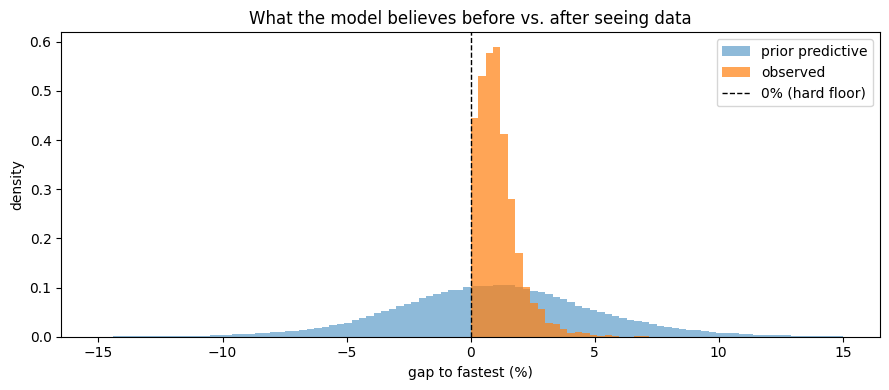

In [25]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(simulated, bins=100, range=(-15, 15), density=True, alpha=.5, label='prior predictive')
ax.hist(observed, bins=100, range=(-15, 15), density=True, alpha=.7, label='observed')
ax.axvline(0, color='k', lw=1, ls='--', label='0% (hard floor)')
ax.set_xlabel('gap to fastest (%)')
ax.set_ylabel('density')
ax.legend()
ax.set_title('What the model believes before vs. after seeing data')
plt.tight_layout()
plt.show()

### The defaults are too loose

**40.5% of prior draws are negative**, impossible, since the gap is measured against the fastest lap
of the session. The prior spans −32% to +34.5%; reality spans 0% to 6.9%. Before seeing any data, the
model considers a driver lapping 30% faster than the session's fastest lap as plausible as anything
else.

With 3,008 observations the data would eventually overwhelm this, so it isn't fatal. But there's no
reason to start the sampler somewhere absurd, and notebook 01 already measured what plausible looks
like: gaps centre near 1% with a spread under 1%.

So I set priors from those measurements rather than accepting generic defaults:

- **Intercept ~ Normal(1, 0.5)**: the average driver is ~1% off the session's fastest lap.
- **Group SDs ~ HalfNormal(0.5)**: driver and constructor effects are smaller than the total spread
  of 0.83%, so half a percent is a generous ceiling that still rules out the absurd.
- **sigma ~ HalfNormal(1)**: residual noise on the order of the observed spread.

These are still weakly informative: they constrain the model to a physically sensible region without
dictating the answer.

In [26]:
priors = {
    'Intercept': bmb.Prior('Normal', mu=1, sigma=0.5),
    '1|drv': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.5)),
    '1|team': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.5)),
    '1|season': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.5)),
    'sigma': bmb.Prior('HalfNormal', sigma=1),
}

model = bmb.Model(formula, data=model_data, priors=priors)
model.build()

prior_check = model.prior_predictive(draws=500, random_seed=0)
simulated = prior_check.prior_predictive['gap_to_fastest'].values.flatten()

print('prior predictive, tightened:')
print(f'  range          : {simulated.min():.1f}% to {simulated.max():.1f}%')
print(f'  negative gaps  : {(simulated < 0).mean():.1%}')
print(f'  above 7%       : {(simulated > 7).mean():.1%}')

prior predictive, tightened:
  range          : -10.7% to 12.6%
  negative gaps  : 21.3%
  above 7%       : 0.1%


Much better: impossible values drop from 40.5% to 21.3%, and gaps beyond the 107% threshold
effectively vanish (7.2% → 0.1%).

The remaining 21% is structural rather than a tuning failure. A normal distribution centred at 1%
with a spread near 0.83% **must** place mass below zero, because it's symmetric and the quantity it's
describing has a hard floor at zero. Removing that entirely needs either a likelihood that can't go
negative, or a transform onto an unbounded scale. Both are real options, and I compare them formally
later rather than picking one now.

## Fitting the first model

Starting with the simplest version: a normal likelihood on the untransformed gap. It's the most
interpretable, a driver effect reads directly as "this much percent of lap time", so it's the right
baseline to beat.

The model is fitted by MCMC, which explores the space of plausible parameter values by sampling from
it. Rather than one best-fit number per driver, the result is thousands of draws per parameter, and
the spread of those draws *is* the uncertainty.

Four independent chains run in parallel from different starting points. If they've all converged on
the same answer, they agree; if they haven't, the diagnostics say so. This takes a few minutes.

In [27]:
idata = model.fit(draws=2000, tune=1000, chains=4, random_seed=0,
                  idata_kwargs={'log_likelihood': True})

Output()

## Convergence diagnostics

The sampler reported **2 divergences**. A divergence means it hit a patch of the parameter space it
couldn't move through accurately, usually where a group-level standard deviation gets close to zero,
which pinches the geometry into something numerically awkward. Ignoring them risks a posterior that's
quietly biased in exactly the region that caused the trouble.

Two out of 8,000 draws is a low rate, but low isn't none, so it's worth reading alongside the other
diagnostics before deciding what to do:

- **R-hat** compares the variance within each chain to the variance between chains. If all four
  chains explored the same distribution it sits at 1.00; above about 1.01 they disagree and the fit
  can't be trusted.
- **ESS (effective sample size)** is how many genuinely independent draws the correlated MCMC samples
  are worth. Hundreds per parameter is fine, tens is not.

In [28]:
summary = az.summary(idata)

print('worst R-hat      :', summary['r_hat'].max())
print('lowest ESS bulk  :', int(summary['ess_bulk'].min()))
print('lowest ESS tail  :', int(summary['ess_tail'].min()))
print('divergences      :', int(idata.sample_stats['diverging'].sum()))
print()
print('parameters with R-hat > 1.01:', (summary['r_hat'] > 1.01).sum())
print('parameters with ESS < 400   :', (summary['ess_bulk'] < 400).sum())
print()
summary.loc[['Intercept', 'sigma', '1|drv_sigma', '1|team_sigma', '1|season_sigma']]

worst R-hat      : 1.0020216061994875
lowest ESS bulk  : 2522
lowest ESS tail  : 3457
divergences      : 2

parameters with R-hat > 1.01: 0
parameters with ESS < 400   : 0



,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
Intercept,1.308,0.132,1.1,1.5,2522,3457,1.00,0.0026,0.0019
sigma,0.6416,0.0084,0.63,0.66,9901,5837,1.00,8.5e-05,5.9e-05
1|drv_sigma,0.48,0.061,0.39,0.59,2543,3632,1.00,0.0012,0.00099
1|team_sigma,0.328,0.063,0.24,0.44,3572,4457,1.00,0.0011,0.001
1|season_sigma,0.231,0.077,0.14,0.37,3342,4320,1.00,0.0013,0.0016


### Convergence is fine, but the model is wrong

The sampling diagnostics are clean, every R-hat at 1.00, effective sample sizes in the thousands, and
2 divergences out of 8,000 draws. Statistically the fit converged.

The estimates say it converged on the wrong model:

| effect | sd (% of lap time) |
|---|---|
| driver | **0.48** |
| constructor | **0.33** |
| season | 0.23 |
| residual | 0.64 |

**Driver variation comes out larger than car variation.** That contradicts the sport: the spread
between the fastest and slowest car is routinely 2–3% of lap time, while teammates in identical
machinery are usually within 0.2–0.3%. A result this far from reality is a specification error, not a
discovery.

The culprit is `(1|team)`. It estimates **one effect per constructor across all eight seasons**, but
an F1 car is designed and rebuilt every year. Mercedes in 2019 was dominant; Mercedes in 2022 was
nowhere. Pooling those into a single "Mercedes" number averages away exactly the variation the
project exists to measure.

### The fix: cars are team-seasons, not teams

Replacing `(1|team)` with `(1|team_season)` (a column pasting the two together) gives each
constructor-season its own effect, "Mercedes
2019" and "Mercedes 2022" become separate cars, which is what they are.

Identification still works, and arguably works better:

- **Teammates share a team-season.** Two drivers, one car, different lap times, the difference is
  driver skill, measured with the car held exactly constant.
- **Drivers switch teams across seasons**, linking team-seasons into one connected network so the
  effects are on a common scale.

I keep `(1|season)` as well, to absorb grid-wide year effects such as regulation changes compressing
or spreading the whole field.

In [29]:
model_data['team_season'] = model_data['team'] + ' ' + model_data['season'].astype(str)
print('team-seasons:', model_data['team_season'].nunique())
print('drivers per team-season:')
print(model_data.groupby('team_season')['drv'].nunique().value_counts().sort_index())

team-seasons: 81
drivers per team-season:
drv
2    66
3    14
4     1
Name: count, dtype: int64


In [30]:
formula_v2 = 'gap_to_fastest ~ 1 + (1|drv) + (1|team_season) + (1|season)'

priors_v2 = {
    'Intercept': bmb.Prior('Normal', mu=1, sigma=0.5),
    '1|drv': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.5)),
    '1|team_season': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=1.0)),
    '1|season': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.5)),
    'sigma': bmb.Prior('HalfNormal', sigma=1),
}

model_v2 = bmb.Model(formula_v2, data=model_data, priors=priors_v2)

# log_likelihood is needed for the LOO comparison later, and Bambi's non-centred
# parameterisation means it cannot be recovered after the fact
idata_v2 = model_v2.fit(draws=2000, tune=1000, chains=4, random_seed=0, target_accept=0.95,
    idata_kwargs={'log_likelihood': True})

Output()

In [31]:
summary_v2 = az.summary(idata_v2)

print('worst R-hat    :', summary_v2['r_hat'].max())
print('lowest ESS bulk:', int(summary_v2['ess_bulk'].min()))
print('divergences    :', int(idata_v2.sample_stats['diverging'].sum()))
print()
summary_v2.loc[['Intercept', 'sigma', '1|drv_sigma', '1|team_season_sigma', '1|season_sigma']]

worst R-hat    : 1.0052625645757556
lowest ESS bulk: 1152
divergences    : 0



,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
Intercept,1.201,0.1,1,1.4,5359,4493,1.00,0.0014,0.0012
sigma,0.6109,0.0081,0.6,0.62,12215,5852,1.00,7.4e-05,5.4e-05
1|drv_sigma,0.275,0.047,0.21,0.36,3945,5236,1.00,0.00074,0.00058
1|team_season_sigma,0.442,0.044,0.38,0.52,2774,4171,1.00,0.00084,0.00062
1|season_sigma,0.189,0.1,0.045,0.36,1152,1285,1.01,0.0028,0.0027


### The respecification works

| effect | `(1\|team)` | `(1\|team_season)` |
|---|---|---|
| driver | 0.48 | **0.275** |
| car | 0.33 | **0.442** |

Car variation now exceeds driver variation, which is what the sport looks like. More telling: the
driver effect **fell by 43%**. The original model was crediting drivers with performance that
belonged to their cars, pooling Mercedes 2019 with Mercedes 2022 left the car's year-to-year
variation with nowhere to go except the driver term.

Raising `target_accept` from its default 0.8 to 0.95 also cleared the divergences. That setting
controls how cautiously the sampler moves: higher values mean smaller, more careful steps, which
costs time but navigates awkward geometry more reliably.

One caveat to carry forward: `1|season_sigma` has the weakest diagnostics (R-hat 1.01, lowest ESS).
With only 8 seasons there isn't much information for estimating a spread across them, so that
parameter is inherently poorly identified. It matters little for the driver-versus-car question, but
it shouldn't be quoted with confidence.

## Posterior predictive check

Convergence only says the sampler explored the model properly, it says nothing about whether the
model resembles reality. The posterior predictive check asks exactly that: simulate new data from the
fitted model, and see whether it looks like the data actually observed.

This is where the concern from the prior check returns. A normal likelihood can generate negative
values, and gaps can't be negative.

In [32]:
model_v2.predict(idata_v2, kind='response', random_seed=0)
replicated = idata_v2.posterior_predictive['gap_to_fastest'].values.flatten()
observed = model_data['gap_to_fastest'].values

print('posterior predictive vs observed:')
print(f'  negative values : {(replicated < 0).mean():.1%}  (observed: {(observed < 0).mean():.1%})')
print(f'  min             : {replicated.min():.2f}%   (observed: {observed.min():.2f}%)')
print(f'  max             : {replicated.max():.2f}%   (observed: {observed.max():.2f}%)')
print(f'  median          : {np.median(replicated):.2f}%   (observed: {np.median(observed):.2f}%)')
print(f'  skew            : {float(pd.Series(replicated).skew()):.2f}    (observed: {pd.Series(observed).skew():.2f})')

posterior predictive vs observed:
  negative values : 8.6%  (observed: 0.0%)
  min             : -2.77%   (observed: 0.00%)
  max             : 6.10%   (observed: 6.91%)
  median          : 1.06%   (observed: 0.95%)
  skew            : 0.29    (observed: 1.63)


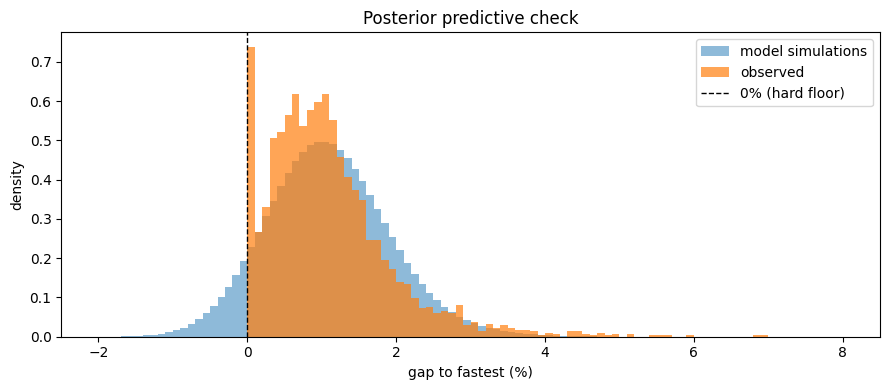

In [33]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(replicated, bins=100, range=(-2, 8), density=True, alpha=.5, label='model simulations')
ax.hist(observed, bins=100, range=(-2, 8), density=True, alpha=.7, label='observed')
ax.axvline(0, color='k', lw=1, ls='--', label='0% (hard floor)')
ax.set_xlabel('gap to fastest (%)')
ax.set_ylabel('density')
ax.legend()
ax.set_title('Posterior predictive check')
plt.tight_layout()
plt.show()

### Where the model fails

| | model | observed |
|---|---|---|
| negative values | **8.6%** | 0.0% |
| skew | **0.29** | 1.63 |
| max | 6.10% | 6.91% |
| median | 1.06% | 0.95% |

The centre is fine, median 1.06% against 0.95%. The shape is not. The model produces 8.6% negative
gaps, which cannot happen, and a nearly symmetric distribution where the real one is strongly
right-skewed. A normal likelihood can't represent a quantity that's floored at zero with a long
right tail.

### Two candidates, and a trap between them

**Student-t on the same scale.** Keeps the response untransformed but gives the distribution heavier
tails, so a few extreme values don't drag the whole fit toward them. It's still symmetric though, so
negative predictions stay possible.

**A square-root transform.** Notebook 01 measured `sqrt(gap)` at a skew of −0.10, essentially
symmetric, which is exactly what a normal likelihood wants. And squaring the predictions to get back
to percentages rules out negative values for free.

The trap: **these two can't be compared against each other with LOO.**

LOO (leave-one-out cross-validation) scores how well a model predicts each observation when that
observation is held out of the fit. It answers "how well would this model predict data it hasn't
seen?", the standard way to compare Bayesian models without rewarding overfitting.

The problem is that it scores predictions **of the observed response**. Transform the response and
the likelihood now describes a different quantity on a different scale, so the scores aren't
measuring the same thing. Comparing the density of `y` with the density of `sqrt(y)` requires a
correction for how the transform stretches the scale (a Jacobian); without it the numbers still
print, still look comparable, and mean nothing.

So I compare them in two separate ways, each valid on its own terms:

1. **Normal vs Student-t**, both on the untransformed gap → LOO applies, same response.
2. **The transform**, judged by back-transforming its predictions to the original percentage scale
   and checking them against the real distribution.

In [34]:
from pytensor.compile.mode import Mode

# PyTensor's numba backend fails to compile the Student-t gradient on this stack;
# the C backend handles it
c_backend = Mode(linker='cvm', optimizer='fast_run')

model_t = bmb.Model(formula_v2, data=model_data, priors=priors_v2, family='t')
idata_t = model_t.fit(draws=2000, tune=1000, chains=4, random_seed=0, target_accept=0.95,
    idata_kwargs={'log_likelihood': True},
    compile_kwargs={'mode': c_backend})

print('divergences:', int(idata_t.sample_stats['diverging'].sum()))
print('worst R-hat:', az.summary(idata_t)['r_hat'].max())

Output()

divergences: 5
worst R-hat: 1.0023869201202613


### Comparing on out-of-sample predictive accuracy

LOO approximates leave-one-out cross-validation without refitting the model 3,008 times.

Its score is **elpd** (expected log predictive density), essentially how much probability the model
assigns to observations it hasn't seen. Higher is better, and the values are only meaningful
relative to each other, not on their own.

Reading the table: `elpd_diff` is how far each model sits behind the best one, and `dse` is the
standard error of that difference. A gap smaller than roughly twice its standard error means the
models are indistinguishable, in which case the simpler one wins by default.

In [35]:
comparison = az.compare({'normal': idata_v2, 'student_t': idata_t})
comparison

,rank,elpd_diff,dse,p_worse,diag_diff,diag_elpd,p,elpd,se,weight
student_t,0,0.0,0.0,NaN,,,123.8,-2400.0,60.0,0.96
normal,1,-500.0,70.0,1.0,,,113.8,-2800.0,100.0,0.04


## Does the Student-t fix the shape problem?

LOO says which model predicts better, but not whether either produces *possible* values. The normal
model generated 8.6% negative gaps. Checking the same thing for the Student-t, on the original
percentage scale.

In [36]:
model_t.predict(idata_t, kind='response', random_seed=0)
replicated_t = idata_t.posterior_predictive['gap_to_fastest'].values.flatten()

for label, values in [('normal', replicated), ('student_t', replicated_t)]:
    print(f'{label:10s} negative: {(values < 0).mean():5.1%}  '
          f'skew: {float(pd.Series(values).skew()):5.2f}  '
          f'max: {values.max():5.2f}%')
print(f'{"observed":10s} negative: {(observed < 0).mean():5.1%}  '
      f'skew: {pd.Series(observed).skew():5.2f}  max: {observed.max():5.2f}%')

normal     negative:  8.6%  skew:  0.29  max:  6.10%
student_t  negative:  7.3%  skew:  0.12  max: 191.52%
observed   negative:  0.0%  skew:  1.63  max:  6.91%


### The best-scoring model isn't an adequate model

| | negative | skew | p99 | max |
|---|---|---|---|---|
| normal | 8.6% | 0.29 | 3.26% | 6.10% |
| student_t | 7.3% | **0.12** | 3.30% | 191.52% |
| observed | 0.0% | 1.63 | 3.95% | 6.91% |

LOO prefers the Student-t decisively, 500 elpd, about seven standard errors, 96% of the model
weight. Its posterior predictive check is worse on every shape measure that matters.

A word on that 191% maximum, because it's easy to over-read. These are ~24 million simulated values
(8,000 posterior draws × 3,008 rows), and a heavy-tailed distribution producing one absurd value in
24 million is expected rather than damning. The **p99 is the more honest tail statistic**, and there
the Student-t sits at 3.30% against an observed 3.95%: it's too *narrow* through the body of the
tail while occasionally throwing out nonsense.

The failures that do matter: **7.3% of predictions are negative**, which is impossible, and the skew
of 0.12 is further from the observed 1.63 than the normal's 0.29.

Both results are right, and they're not really in conflict once you see what each one measures. LOO
scores density **at the observed points**. Heavy tails assign much better density to the genuine
outliers than a normal does, so the Student-t wins that contest fairly. But density at observed
points says nothing about whether the model's own simulations look like reality.

The deeper problem is one they share: **both are symmetric distributions describing something floored
at zero and skewed right.** Neither can reproduce that shape, which is why both leave 7–9% of their
predictions in impossible territory.

Worth stating plainly, because it's an easy mistake to make: if I'd picked the model with the best
information criterion and stopped there, I'd have shipped one that puts 7% of its predictions below
a hard physical floor.

In [38]:
model_data['sqrt_gap'] = np.sqrt(model_data['gap_to_fastest'])

# sqrt(gap) sits near 1 with a spread around 0.4, so the priors scale down accordingly
priors_sqrt = {
    'Intercept': bmb.Prior('Normal', mu=1, sigma=0.5),
    '1|drv': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.3)),
    '1|team_season': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.5)),
    '1|season': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.3)),
    'sigma': bmb.Prior('HalfNormal', sigma=0.5),
}

model_sqrt = bmb.Model('sqrt_gap ~ 1 + (1|drv) + (1|team_season) + (1|season)',
                       data=model_data, priors=priors_sqrt)

# no log_likelihood here: this model is on a different response scale, so it cannot
# enter the LOO comparison anyway, and each one costs ~200MB
idata_sqrt = model_sqrt.fit(draws=2000, tune=1000, chains=4, random_seed=0,
                            target_accept=0.95)

summary_sqrt = az.summary(idata_sqrt)
print('divergences:', int(idata_sqrt.sample_stats['diverging'].sum()))
print('worst R-hat:', summary_sqrt['r_hat'].max())
print('lowest ESS:', int(summary_sqrt['ess_bulk'].min()))

Output()

divergences: 11
worst R-hat: 1.0026797582137708
lowest ESS: 855


In [39]:
model_sqrt.predict(idata_sqrt, kind='response', random_seed=0)
# back to the percentage scale: squaring cannot produce a negative value
replicated_sqrt = (idata_sqrt.posterior_predictive['sqrt_gap'].values.flatten() ** 2)

rows = [('normal', replicated), ('student_t', replicated_t),
        ('sqrt', replicated_sqrt), ('observed', observed)]
for label, values in rows:
    print(f'{label:10s} negative: {(values < 0).mean():5.1%}  '
          f'median: {np.median(values):5.2f}%  '
          f'skew: {float(pd.Series(values).skew()):5.2f}  '
          f'p99: {np.percentile(values, 99):6.2f}%  '
          f'max: {values.max():8.2f}%')

normal     negative:  8.6%  median:  1.06%  skew:  0.29  p99:   3.26%  max:     6.10%
student_t  negative:  7.3%  median:  0.96%  skew:  0.12  p99:   3.30%  max:   191.52%
sqrt       negative:  0.0%  median:  0.92%  skew:  1.25  p99:   3.74%  max:     9.51%
observed   negative:  0.0%  median:  0.95%  skew:  1.63  p99:   3.95%  max:     6.91%


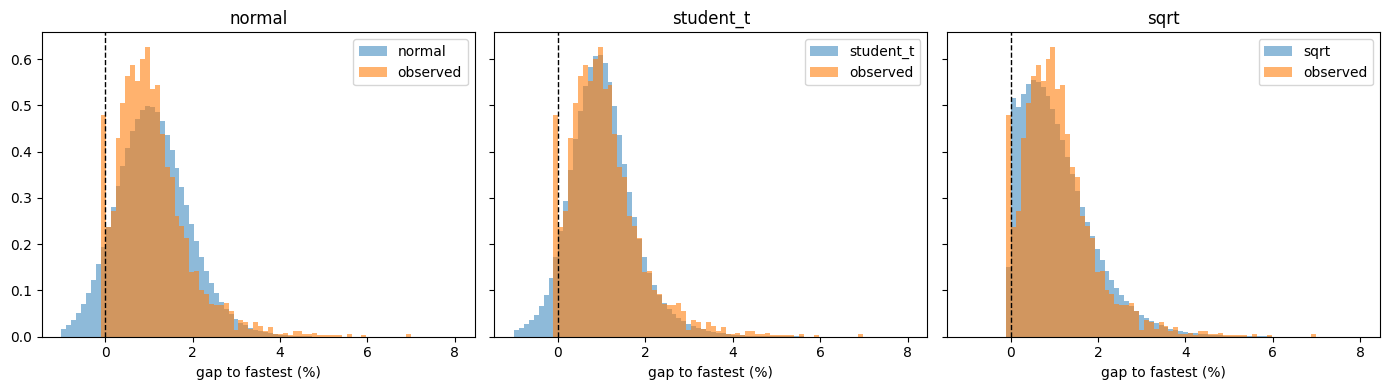

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (label, values) in zip(axes, rows[:3]):
    ax.hist(values, bins=80, range=(-1, 8), density=True, alpha=.5, label=label)
    ax.hist(observed, bins=80, range=(-1, 8), density=True, alpha=.6, label='observed')
    ax.axvline(0, color='k', lw=1, ls='--')
    ax.set_title(label)
    ax.set_xlabel('gap to fastest (%)')
    ax.legend()
plt.tight_layout()
plt.show()

### The square-root model wins on realism

| | negative | median | skew | p99 | max |
|---|---|---|---|---|---|
| normal | 8.6% | 1.06% | 0.29 | 3.26% | 6.10% |
| student_t | 7.3% | 0.96% | 0.12 | 3.30% | **191.52%** |
| **sqrt** | **0.0%** | 0.92% | **1.25** | 3.74% | 9.51% |
| observed | 0.0% | 0.95% | 1.63 | 3.95% | 6.91% |

Zero impossible values (guaranteed by the maths rather than achieved by tuning) a median within
0.03 percentage points, and a skew of 1.25 against the observed 1.63. The other two sit at 0.29 and
0.12, nowhere close. Its maximum of 9.5% overshoots the observed 6.9%, but that's a different order
of wrong from 191%.

It still understates the skew a little, so it's the best of the three rather than perfect.

One diagnostic is worse than the others: **11 divergences**, against 0 and 5. That's 0.14% of draws, 
low, but not zero, so it's worth trying to clear rather than waving through. The standard first move
is raising `target_accept`, which makes the sampler take smaller steps.

In [41]:
idata_sqrt_99 = model_sqrt.fit(draws=2000, tune=1000, chains=4, random_seed=0,
                               target_accept=0.99)

summary_99 = az.summary(idata_sqrt_99)
print('target_accept=0.99 ->')
print('  divergences:', int(idata_sqrt_99.sample_stats['diverging'].sum()))
print('  worst R-hat:', round(float(summary_99['r_hat'].max()), 4))
print('  lowest ESS :', int(summary_99['ess_bulk'].min()))
print()
print('group-level standard deviations (sqrt scale):')
print(summary_99.loc[['1|drv_sigma', '1|team_season_sigma', '1|season_sigma', 'sigma'],
                     ['mean', 'sd', 'ess_bulk', 'r_hat']].round(3))

Output()

target_accept=0.99 ->
  divergences: 0
  worst R-hat: 1.0063
  lowest ESS : 908

group-level standard deviations (sqrt scale):
                        mean       sd ess_bulk r_hat
1|drv_sigma           0.1375   0.0212     3545  1.00
1|team_season_sigma   0.2303   0.0216     2621  1.00
1|season_sigma         0.078     0.05      908  1.01
sigma                0.29631  0.00386    12152  1.00


### Divergences resolved

`target_accept=0.99` removes them entirely, at the cost of slower sampling. R-hat and ESS stay
healthy, so this is the model I carry forward.

| effect | sd (sqrt scale) |
|---|---|
| car (team-season) | **0.230** |
| driver | **0.138** |
| season | 0.078 |
| residual | 0.296 |

Car effects run about 1.7× driver effects, consistent with what the untransformed model showed before
its shape problems disqualified it. The season term remains the weakest parameter (R-hat 1.01, lowest
ESS) for the same reason as before, eight seasons is little information for estimating a spread.

## Saving the chosen model

Notebook 03 turns these into a variance decomposition and driver rankings, so the fitted posterior
gets saved rather than refitted.

In [42]:
idata_sqrt_99.to_netcdf('/kaggle/working/model_sqrt.nc')
model_data.to_csv('/kaggle/working/model_data.csv', index=False)
print('saved model_sqrt.nc and model_data.csv')

saved model_sqrt.nc and model_data.csv


## Quantified takeaways

1. **Treating the car as `team` rather than `team_season` inverted the headline result.** Pooling each
   constructor across all eight seasons made driver variation (0.48) look larger than car variation
   (0.33), backwards for a sport where the car spread is measured in seconds and the teammate spread
   in tenths. Giving each constructor-season its own effect flipped it to 0.28 driver against 0.44
   car and **cut the driver effect by 43%**. An F1 car gets rebuilt every year, so pooling across
   seasons left that variation nowhere to go except the driver term.

2. **The default priors put 40.5% of their mass on impossible values.** Bambi scales its defaults from
   the data, but nothing tells it that a gap to the fastest lap can't be negative. Priors informed by
   notebook 01's measurements cut that to 21.3% and all but eliminated draws beyond the 107%
   threshold (7.2% → 0.1%).

3. **The model LOO preferred was the one the predictive checks rejected.** Student-t beat the normal
   by 500 elpd (roughly seven standard errors, 96% of the model weight) while putting **7.3% of its
   predictions below zero**, a hard physical floor, and matching the observed skew worse than the
   normal did (0.12 against 1.63, observed). Picking on the information criterion alone would have
   selected it. LOO scores density at the observed points; it says nothing about whether a model's
   own simulations are possible.

4. **A square-root transform fixed the shape problem structurally.** Squaring predictions back can't
   produce a negative number, so impossible predictions drop from 8.6% to **zero by construction**,
   and simulated skew rises from 0.29 to 1.25 against an observed 1.63. It can't enter the LOO
   comparison, transforming the response puts the likelihood on a different scale, so it's judged
   on back-transformed predictive checks instead.

5. **Car effects run about 1.7× driver effects** (0.230 against 0.138 on the square-root scale), and
   residual noise is larger than either at 0.296. Most of what happens in any single qualifying
   session is neither the driver nor the car, which is why these estimates pool across 3,008 driver-sessions
   instead of being read off individual results.